In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from sklearn.model_selection import train_test_split
import torch
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.nn.functional as F
import pandas as pd
from scipy.spatial.distance import euclidean
import numpy as np
import time
import matplotlib.pyplot as plt
from torch.nn import Module

In [3]:
class CNN_GRU_Model(nn.Module):
    def __init__(self, time_lag=72, pred_horizon=4, num_stations=9):
        super(CNN_GRU_Model, self).__init__()

        self.pred_horizon = pred_horizon
        self.num_stations = num_stations

        # 3D Convolution Layer
        cnn_out_channels = 64
        self.conv3d = nn.Conv3d(in_channels=1, out_channels=cnn_out_channels, kernel_size=(1, 4, 1))
        self.activation = nn.SELU()

        # GRU Layer
        hidden_size=64 * num_stations * pred_horizon
        self.gru = nn.GRU(input_size=num_stations*cnn_out_channels, hidden_size=hidden_size, num_layers=2, batch_first=True, dropout=0.02)

        # Fully connected layer for main model output
        fc_main_output_size = 250
        self.fc_main = nn.Linear(hidden_size, fc_main_output_size)

        # Fully connected layer for auxiliary input (72, 3) -> flattened and mapped to 100 neurons
        aux_data_len=3
        fc_aux_output_size=100
        self.fc_aux = nn.Linear(time_lag * aux_data_len, fc_aux_output_size)

        # Fully connected layer after concatenating the main and aux inputs
        fc_concat1_output_size = 100
        self.fc_concat1 = nn.Linear(fc_main_output_size+fc_aux_output_size, fc_concat1_output_size)
        self.fc_concat2 = nn.Linear(fc_concat1_output_size, num_stations * pred_horizon)

    def forward(self, x, aux_input):
        # Main model (CNN + GRU)
        x = x.unsqueeze(1)  # Shape: (batch_size, 1, 9, 4, 12)
        x = self.conv3d(x)  # Shape: (batch_size, 64, 9, 1, 12)
        x = self.activation(x)
        x = x.permute(0, 4, 1, 2, 3).contiguous()  # Shape: (batch_size, 12, 64, 9, 1)
        x = x.view(x.size(0), x.size(1), -1)  # Shape: (batch_size, 12, 64 * 9)
        x, _ = self.gru(x)  # Shape: (batch_size, time_lag, hidden_size)
        x = x[:, -1, :]  # Take the last time step's output -> Shape: (batch_size, hidden_size)
        x = self.fc_main(x)  # Shape: (batch_size, 250)

        # Auxiliary input processing (flatten first)
        aux_input = aux_input.view(aux_input.size(0), -1)  # Flatten (batch_size, 72 * 3)
        aux_out = self.fc_aux(aux_input)  # Shape: (batch_size, 100)
        aux_out = self.activation(aux_out)

        # Concatenate the main model output and auxiliary input
        combined = torch.cat((x, aux_out), dim=1)  # Shape: (batch_size, 250 + 100)

        # Final fully connected layer to get output (batch_size, 9 * 5)
        output = self.fc_concat1(combined)  # Shape: (batch_size, 9 * 5)
        output = self.activation(output)
        output = self.fc_concat2(output)
        output = output.view(output.size(0), self.num_stations, self.pred_horizon)  # Reshape to (batch_size, 9, 5)

        return output

    def train_model_early_stop(self, num_epochs, train_loader, valid_loader, batch_size, optimizer, criterion, device, patience=7):
        last_valid_loss = float('inf')
        epochs_no_improve = 0
        early_stop = False

        train_loss_history = []
        val_loss_history = []
        start_time = time.time()
        trained_epochs = 0

        for epoch in range(num_epochs):
            if early_stop:
                break
            trained_epochs += 1
            train_epoch_iterator = tqdm(train_loader, desc="Training")
            epoch_loss = self.train_epoch(train_epoch_iterator, optimizer, criterion, device)
            val_loss = self.get_eval_factors(valid_loader, batch_size, criterion, device)

            train_loss_history += [epoch_loss]
            val_loss_history += [val_loss]

            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}')

        # Early stopping
            if val_loss < last_valid_loss:
                last_valid_loss = val_loss
                epochs_no_improve = 0
                best_model_wts = self.state_dict()
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f'Early stopping triggered after {epoch+1} epochs')
                early_stop = True

        end_time = time.time()
        training_time = end_time - start_time
        print(f'Total Training Time: {training_time:.2f} seconds')

        if early_stop:
            self.load_state_dict(best_model_wts)

        return (train_loss_history, val_loss_history, trained_epochs)

    def train_epoch(self, train_loader, optimizer, criterion, device):
        self.train()
        running_loss = 0.0
        total_samples = 0


        for inputs, aux_inputs, targets in train_loader:
            inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = self(inputs, aux_inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * targets.size(0)
            total_samples += targets.size(0)
            train_loader.set_postfix({'train loss': loss.item()})

        epoch_loss = running_loss / total_samples
        return epoch_loss

    def get_eval_factors(self, val_loader, batch_size, criterion, device):
        self.eval()
        total_loss = 0
        total_samples = 0

        with torch.no_grad():
            for inputs, aux_inputs, targets in val_loader:
                inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
                outputs = model(inputs, aux_inputs)
                loss = criterion(outputs, targets)

                total_loss += loss.item() * targets.size(0)
                total_samples += targets.size(0)

        val_loss = total_loss / total_samples

        return val_loss

In [11]:
def calculate_dtw(df1, df2):
    series1 = df1.to_numpy()
    series2 = df2.to_numpy()

    distance, _ = fastdtw(series1, series2, dist=euclidean)
    return distance

def append_time_if_missing(date_str):
    if len(date_str) == 10:  # 'yy-mm-dd' has a length of 10
        return date_str + ' 00:00:00'
    else:
        return date_str

def prepare_data(r=12, b=5):
  pm25_data = df['PM2.5'].values
  pm25_data = (pm25_data - pm25_data.min()) / (pm25_data.max() - pm25_data.min())
  station_counts = df['Station'].value_counts().reindex(range(1, 10), fill_value=0)
  total_data = station_counts[1]

  inputs = []
  outputs = []
  aux_inputs = []
  aux_data = []

  for column in aux_df.columns:
    if column != 'date':
      aux_df[column] = (aux_df[column] - aux_df[column].min()) / (aux_df[column].max() - aux_df[column].min())

  for index, row in aux_df.iterrows():
    row_values = row.tolist()
    aux_data.append(row_values[1:])

  print(len(aux_data))
  print(total_data)

  for i in range(0, total_data - r - b + 1, 2):
      input = []
      output = []
      for j in range(9):
        inp = []
        out = []
        np.append(similars[j],j + 1)
        for k in similars[j]:
          inp.append(pm25_data[(k - 1) * total_data + i:(k - 1) * total_data + i + r])
          out.append(pm25_data[(k - 1) * total_data + i + r:(k - 1) * total_data + i + r + b])
        input.append(inp)
        output.append(out[-1])
      inputs.append(input)
      outputs.append(output)
      aux_slice = aux_data[i:i + r]  # Get slice of aux_data
      aux_inputs.append(np.array(aux_slice))

  inputs = np.array(inputs)
  outputs = np.array(outputs)
  aux_inputs = np.array(aux_inputs)
  return inputs, outputs, aux_inputs

In [12]:
class PM25Dataset(Dataset):
    def __init__(self, x_data, aux_data, y_data, transform=None):
        self.x_data = x_data
        self.aux_data = aux_data
        self.y_data = y_data
        self.transform = transform

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        x = self.x_data[idx]
        aux = self.aux_data[idx]
        y = self.y_data[idx]

        if self.transform:
            x = self.transform(x)

        return torch.tensor(x, dtype=torch.float32), torch.tensor(aux, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

In [13]:
# read pm25 dataframe, replace outliers

df =  pd.read_csv('/content/drive/MyDrive/Air Polution Research/preprocessed_data.csv')
df = df.sort_values(by=['Station', 'Date'], ascending=[True, True])

lower_bound = 4
upper_bound = 96

outliers_count = ((df['PM2.5'] < lower_bound) | (df['PM2.5'] > upper_bound)).sum()


df['PM2.5'] = df['PM2.5'].where((df['PM2.5'] >= lower_bound) & (df['PM2.5'] <= upper_bound), np.nan)

print(f"Number of outliers replaced: {outliers_count}")
df['PM2.5'] = df['PM2.5'].ffill().bfill()

pm25_data = df['PM2.5'].values
print(pm25_data.min(), pm25_data.max())

Number of outliers replaced: 15438
4.0 96.0


In [ ]:
similars_df = pd.read_csv('/content/drive/MyDrive/Air Polution Research/similars.csv')
similars = similars_df.to_numpy()

In [14]:
# read aux dataframe, choose similar dates, fill nans

aux_df = pd.read_csv('/content/drive/MyDrive/Air Polution Research/IsfMet.csv')
aux_df['date'] = aux_df['date'].apply(append_time_if_missing)
filtered_aux_df = aux_df[aux_df['date'].isin(df['Date'])]
filtered_aux_df = filtered_aux_df[['date', 'ws', 'wd', 'air_temp']]
aux_df = filtered_aux_df
aux_df = aux_df.ffill().bfill()

In [15]:
time_lag = 72
pred_horizon = 1
num_epochs = 30
batch_size = 32

In [16]:
# create datasets

inputs, outputs, aux = prepare_data(r = time_lag, b = pred_horizon)

train_inputs, temp_inputs, train_outputs, temp_outputs, train_aux, temp_aux = train_test_split(inputs, outputs, aux, test_size=0.2, random_state=42, shuffle=True)

val_inputs, test_inputs, val_outputs, test_outputs, val_aux, test_aux = train_test_split(temp_inputs, temp_outputs, temp_aux, test_size=0.2, random_state=42, shuffle=True)

print(train_inputs[0].shape, train_aux[0].shape)

23470
23470
(9, 4, 72) (72, 3)


In [17]:
# Create TensorDataset and DataLoader for training and validation
train_dataset = PM25Dataset(train_inputs, train_aux, train_outputs)
val_dataset = PM25Dataset(val_inputs, val_aux, val_outputs)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [18]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [19]:
# Define model, loss function, and optimizer
model = CNN_GRU_Model(time_lag=time_lag, pred_horizon=pred_horizon)
model = model.to(device)
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [20]:
(train_loss_history, val_loss_history, trained_epochs) = model.train_model_early_stop(num_epochs, train_loader, val_loader,
                                                                                      batch_size, optimizer, criterion, device, patience=3)

Training: 100%|██████████| 293/293 [00:08<00:00, 34.44it/s, train loss=0.0536]


Epoch [1/30], Train Loss: 0.0807, Val Loss: 0.0768


Training: 100%|██████████| 293/293 [00:08<00:00, 36.29it/s, train loss=0.0565]


Epoch [2/30], Train Loss: 0.0683, Val Loss: 0.0634


Training: 100%|██████████| 293/293 [00:08<00:00, 35.68it/s, train loss=0.0625]


...

Epoch [9/30], Train Loss: 0.0578, Val Loss: 0.0628


Training: 100%|██████████| 293/293 [00:08<00:00, 35.59it/s, train loss=0.0442]


Epoch [10/30], Train Loss: 0.0573, Val Loss: 0.0639


Training: 100%|██████████| 293/293 [00:08<00:00, 35.44it/s, train loss=0.0658]


Epoch [11/30], Train Loss: 0.0560, Val Loss: 0.0666
Early stopping triggered after 11 epochs
Total Training Time: 98.01 seconds


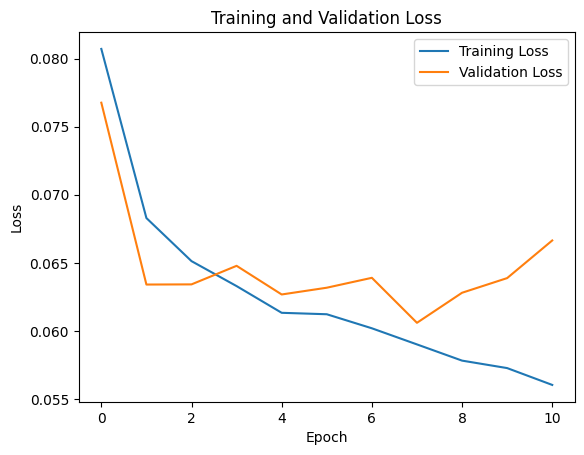

In [21]:
plt.figure()
plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [22]:
model.eval()

idx = 3
aux_single = train_aux[idx]
single_input = train_inputs[idx]  # Shape: (9, 4, 12)
aux_single = torch.tensor(aux_single, dtype=torch.float32)
single_input = torch.tensor(single_input, dtype=torch.float32)

# Add a batch dimension since the model expects a batch
aux_single = aux_single.unsqueeze(0)  # Shape: (1, 9, 4, 12)
single_input = single_input.unsqueeze(0)  # Shape: (1, 9, 4, 12)

# Make sure no gradients are computed during inference
aux_single = aux_single.to(device)
single_input = single_input.to(device)
with torch.no_grad():
    prediction = model(single_input, aux_single)

# `prediction` now contains the output for this single input
print("Prediction:", prediction)
print("Real:", train_outputs[idx])

Prediction: tensor([[[0.5880],
         [0.5630],
         [0.2524],
         [0.2625],
         [0.2285],
         [0.2136],
         [0.2598],
         [0.2025],
         [0.2146]]], device='cuda:0')
Real: [[0.39945652]
 [0.39945652]
 [0.15684783]
 [0.15217391]
 [0.15217391]
 [0.15217391]
 [0.14521739]
 [0.17391304]
 [0.17391304]]


In [23]:
import torch
from sklearn.metrics import r2_score

# Assuming your val_loader provides (inputs, aux_inputs, targets)
all_targets = []
all_predictions = []

# Put model in evaluation mode
model.eval()

# Accumulate predictions and targets
with torch.no_grad():
    for inputs, aux_inputs, targets in val_loader:
        inputs, aux_inputs, targets = inputs.to(device), aux_inputs.to(device), targets.to(device)
        # Forward pass
        outputs = model(inputs, aux_inputs)  # outputs shape: (batch_size, 9, 1)

        # Store predictions and targets
        all_predictions.append(outputs.squeeze(-1).cpu())  # shape: (batch_size, 9)
        all_targets.append(targets.cpu())  # shape: (batch_size, 9)

# Concatenate all batches
all_predictions = torch.cat(all_predictions, dim=0)  # shape: (num_samples, 9)
all_targets = torch.cat(all_targets, dim=0)  # shape: (num_samples, 9)

# Compute R² for each of the 9 outputs
r2_scores = []
for i in range(9):
    pred = all_predictions[:, i].numpy()  # Predictions for station i
    actual = all_targets[:, i].numpy()    # Actual values for station i
    r2 = r2_score(actual, pred)
    r2_scores.append(r2)

# Print R² scores for each of the 9 stations
for i, r2 in enumerate(r2_scores):
    print(f'R² for station {i+1}: {r2:.4f}')

# Print the mean of R² scores
print('Mean of R² scores:', sum(r2_scores)/len(r2_scores))


R² for station 1: 0.8754
R² for station 2: 0.8769
R² for station 3: 0.8691
R² for station 4: 0.6871
R² for station 5: 0.6764
R² for station 6: 0.6895
R² for station 7: 0.8574
R² for station 8: 0.6958
R² for station 9: 0.7038
Mean of R² scores: 0.7701554638223617


In [ ]:
# prompt: display the distribution of data in each station next to each other

import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame containing the PM2.5 data and 'Station' column

# Group the data by station
station_groups = df.groupby('Station')['PM2.5']

# Create subplots
fig, axes = plt.subplots(1, 9, figsize=(20, 5))

# Plot the distribution for each station
for i, (station, data) in enumerate(station_groups):
    axes[i].hist(data, bins=20)
    axes[i].set_title(f'Station {station}')

plt.tight_layout()
plt.show()
